**1. Import Libraries**

In [10]:
import pandas as pd
import numpy as np

**2. Load dataset**

In [26]:
df = pd.read_csv("Dataset_ATS_v2.csv")

**3. View the Data**
*show the first 5 rows of the dataset.*

In [32]:
df.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1,Male,0,No,41,Yes,No,DSL,One year,25,No
2,Female,0,Yes,52,Yes,No,DSL,Month-to-month,19,No
3,Female,0,No,1,Yes,No,DSL,One year,76,Yes
4,Male,0,No,67,Yes,No,Fiber optic,Month-to-month,51,No


**4. Check dataset size**

In [37]:
df.shape

(7043, 10)

**5. Check Column Names**

In [40]:
df.columns

Index(['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService',
       'MultipleLines', 'InternetService', 'Contract', 'MonthlyCharges',
       'Churn'],
      dtype='object')

**6.Check Data Types**

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   gender           7043 non-null   object
 1   SeniorCitizen    7043 non-null   int64 
 2   Dependents       7043 non-null   object
 3   tenure           7043 non-null   int64 
 4   PhoneService     7043 non-null   object
 5   MultipleLines    7043 non-null   object
 6   InternetService  7043 non-null   object
 7   Contract         7043 non-null   object
 8   MonthlyCharges   7043 non-null   int64 
 9   Churn            7043 non-null   object
dtypes: int64(3), object(7)
memory usage: 550.4+ KB


**7.Identify Numerical vs Categorical Columns**

In [46]:
df.select_dtypes(include=['object']).columns

Index(['gender', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'Contract', 'Churn'],
      dtype='object')

In [48]:
df.select_dtypes(exclude=['object']).columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='object')

**8: Missing Values Analysis**

In [51]:
df.isnull().sum()

gender             0
SeniorCitizen      0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
Contract           0
MonthlyCharges     0
Churn              0
dtype: int64

In [53]:
df.isnull().sum().sum()

0

**9: Check for Duplicate Records**

In [56]:
df.duplicated().sum()

302

## Data Quality Assessment

### Missing Values
No missing values were identified in the dataset.

### Duplicate Records
The dataset contains 302 duplicate rows.

**10. Investigate Duplicate Records**

In [64]:
duplicates = df[df.duplicated()]
duplicates.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
78,Male,0,No,1,Yes,No,DSL,Month-to-month,20,No
97,Male,0,No,1,Yes,No,DSL,Month-to-month,20,No
352,Male,0,No,1,Yes,No,Fiber optic,Month-to-month,20,No
398,Male,0,No,1,Yes,No,DSL,Month-to-month,20,No
402,Male,0,No,1,Yes,Yes,Fiber optic,Month-to-month,20,Yes


In [66]:
duplicates.shape

(302, 10)

**11. Checking Categorical Values**

In [70]:
for col in df.select_dtypes(include=['object']).columns:
    print(f"\n----- {col} -----")
    print(df[col].value_counts())


----- gender -----
gender
Male      3555
Female    3488
Name: count, dtype: int64

----- Dependents -----
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

----- PhoneService -----
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

----- MultipleLines -----
MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64

----- InternetService -----
InternetService
DSL            3947
Fiber optic    3096
Name: count, dtype: int64

----- Contract -----
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

----- Churn -----
Churn
No     5174
Yes    1869
Name: count, dtype: int64


# Data Profiling Findings

## Dataset Overview
- Rows: 7043
- Columns: 10

## Missing Values
- No missing values detected.

## Duplicate Records
- 302 duplicate records detected.

## Numerical Columns
- SeniorCitizen
- tenure
- MonthlyCharges

## Categorical Columns
- gender
- Dependents
- PhoneService
- MultipleLines
- InternetService
- Contract
- Churn

## Initial Observations
- Dataset contains no null values.
- Duplicate records require further review.
- Categorical values appear consistent.

302 duplicate rows were identified.

Because the dataset does not contain a unique customer identifier,
the duplicates may represent different customers sharing identical attributes.

Duplicates will be reviewed before any removal decision is made.

**12. Understanding the numerical data: Descriptive Statistics and Churn Analysis**

In [77]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.758768
std,0.368612,24.559481,30.091650
min,0.000000,0.000000,18.000000
25%,0.000000,9.000000,36.000000
50%,0.000000,29.000000,70.000000
75%,0.000000,55.000000,90.000000
max,1.000000,72.000000,119.000000


In [79]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [81]:
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

## Key Findings

### Numerical Variables

SeniorCitizen
- Mean: 0.16
- Minimum: 0
- Maximum: 1

Tenure
- Average customer tenure is 32.37 months.
- Minimum tenure is 0 months.
- Maximum tenure is 72 months.

MonthlyCharges
- Average monthly charge is 64.76.
- Minimum charge is 18.
- Maximum charge is 119.

### Churn Analysis

- Customers who stayed: 5,174 (73.46%)
- Customers who churned: 1,869 (26.54%)

### Observations

- The dataset is moderately imbalanced, with approximately 73% non-churn customers and 27% churn customers.
- No missing values were detected.
- 302 duplicate records were identified and require review before removal.
- Categorical values appear consistent and suitable for encoding.

**13. Numerical Feature Analysis**

In [85]:
df[['SeniorCitizen', 'tenure', 'MonthlyCharges']].describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.758768
std,0.368612,24.559481,30.091650
min,0.000000,0.000000,18.000000
25%,0.000000,9.000000,36.000000
50%,0.000000,29.000000,70.000000
75%,0.000000,55.000000,90.000000
max,1.000000,72.000000,119.000000


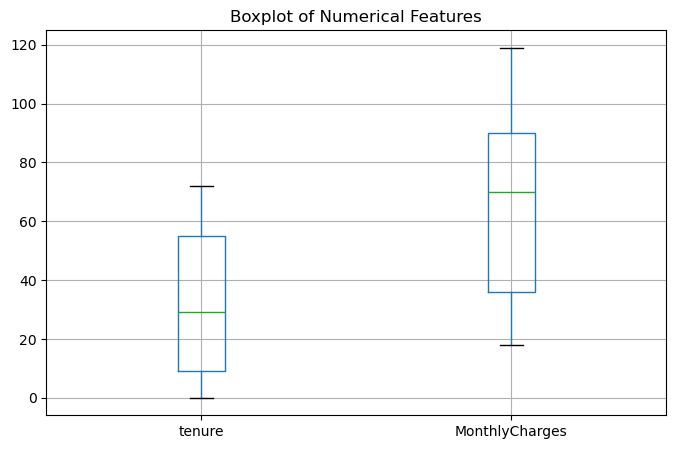

In [87]:
import matplotlib.pyplot as plt

df[['tenure', 'MonthlyCharges']].boxplot(figsize=(8,5))
plt.title("Boxplot of Numerical Features")
plt.show()

## Numerical Feature Analysis Findings

SeniorCitizen
- Binary feature with values 0 and 1.

tenure
- Minimum: 0 months
- Maximum: 72 months
- Average: 32.37 months

MonthlyCharges
- Minimum: 18
- Maximum: 119
- Average: 64.76

Observations
- No obvious extreme outliers observed.
- Values appear realistic and suitable for preprocessing.
- Scaling will likely be required due to differing numerical ranges.

**14. Churn Analysis by Category**

In [91]:
"""Gender VS Churn"""
pd.crosstab(df['gender'], df['Churn'])

Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930


In [93]:
"""Dependents VS Churn"""
pd.crosstab(df['Dependents'], df['Churn'])

Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1784,326


In [97]:
"""PhoneService VS Churn"""
pd.crosstab(df['PhoneService'], df['Churn'])

Churn,No,Yes
PhoneService,,
No,512,170
Yes,4662,1699


In [101]:
"""InternetService VS Churn"""
pd.crosstab(df['InternetService'], df['Churn'])

Churn,No,Yes
InternetService,,
DSL,2865,1082
Fiber optic,2309,787


In [103]:
"""Contract VS Churn"""
pd.crosstab(df['Contract'], df['Churn'])

Churn,No,Yes
Contract,,
Month-to-month,2816,1059
One year,1093,380
Two year,1265,430


### Key Churn Insights

#### Gender
Churn appears relatively similar between male and female customers.

#### Dependents
Customers without dependents appear more likely to churn than customers with dependents.

#### Phone Service
Phone service alone does not appear to strongly influence churn.

#### Internet Service
Both DSL and Fiber Optic customers experience churn, with DSL having a slightly higher churn count.

#### Contract Type
Month-to-month customers show noticeably higher churn compared to customers on one-year or two-year contracts.

### Initial Business Insights

- Contract type appears to be one of the strongest indicators of churn.
- Customers without dependents appear more likely to leave.
- Gender does not appear to have a major influence on churn.
- Additional modelling is required to confirm which variables are most predictive.

**15. Duplicate Record Investigation**

In [108]:
duplicate_percentage = (df.duplicated().sum() / len(df)) * 100

print(f"Duplicate Records: {df.duplicated().sum()}")
print(f"Percentage: {duplicate_percentage:.2f}%")

Duplicate Records: 302
Percentage: 4.29%


In [110]:
df[df.duplicated(keep=False)].sort_values(
    by=['gender','tenure']
).head(20)

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
171,Female,0,No,1,Yes,Yes,Fiber optic,Month-to-month,20,Yes
407,Female,0,No,1,Yes,No,Fiber optic,Month-to-month,20,No
409,Female,0,No,1,Yes,No,DSL,Month-to-month,71,Yes
604,Female,0,No,1,Yes,Yes,Fiber optic,One year,55,Yes
647,Female,0,No,1,Yes,Yes,DSL,One year,20,No
706,Female,0,No,1,Yes,No,DSL,Two year,20,No
734,Female,0,No,1,Yes,Yes,Fiber optic,Month-to-month,20,No
752,Female,0,No,1,Yes,No,DSL,Month-to-month,20,Yes
900,Female,0,No,1,Yes,No,DSL,Month-to-month,45,No


### Duplicate Record Assessment

A total of 302 duplicate records (4.29%) were identified.

The dataset does not contain a unique customer identifier. Therefore, it cannot be confirmed whether these records are true duplicate entries or different customers who happen to share identical attributes.

To avoid removing potentially valid customer records and introducing bias into the analysis, the duplicate records will be retained. This decision and its limitation have been documented.

**16. Preprocessing Strategy**

### Planned Encoding Approach

Binary variables will be encoded using Label Encoding:

- gender
- Dependents
- PhoneService
- MultipleLines
- Churn

Multi-category variables will be encoded using One-Hot Encoding:

- InternetService
- Contract

Numerical variables:

- SeniorCitizen
- tenure
- MonthlyCharges

will remain numerical and may later be standardised using StandardScaler.

**17. Unique Values Review**

In [116]:
for col in df.columns:
    print(f"\n{col}")
    print(df[col].unique())


gender
['Female' 'Male']

SeniorCitizen
[0 1]

Dependents
['No' 'Yes']

tenure
[ 1 41 52 67 68 23 72 70 34 28 18 15 11 37 22 46 51  5 45 29 50 27 60 17
 33 66 69 57  8 14 25  7 13 19 59  9  3 10 39 54 35 12 31 53 30 48 38 65
 24 40 43 71 61 26 42 21 56  4  6 55  2 44 62 63 49 20 16 47 32 64 58 36
  0]

PhoneService
['No' 'Yes']

MultipleLines
['No' 'Yes']

InternetService
['DSL' 'Fiber optic']

Contract
['Month-to-month' 'One year' 'Two year']

MonthlyCharges
[ 25  19  76  51  90  77  72 104  20  84  85  95  54  70  89  80 107  68
  60  92  64  21  94 105 101  55  30 114  98  97  75 103 102  66  74  99
  36  91 108  96  82  35  50  45  24  69  53  40  93 106  44  78  65  71
  79  86  26  83  58  46  81  56 109 100  49  57 117  63 112  67  61 110
  88  62  59  52 115 111  34 113  33  48  23  28  42 116  29  73  87  39
  38  32 118 119  31  41  43  27  47  37  18]

Churn
['Yes' 'No']


**18. Dataset Preparation**

In [119]:
df_clean = df.copy()

In [121]:
df_clean.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1,Male,0,No,41,Yes,No,DSL,One year,25,No
2,Female,0,Yes,52,Yes,No,DSL,Month-to-month,19,No
3,Female,0,No,1,Yes,No,DSL,One year,76,Yes
4,Male,0,No,67,Yes,No,Fiber optic,Month-to-month,51,No


**19. Binary Feature Encoding**

In [124]:
binary_mapping = {
    'Female': 0,
    'Male': 1,
    'No': 0,
    'Yes': 1
}


In [126]:
df_clean['gender'] = df_clean['gender'].map(binary_mapping)

df_clean['Dependents'] = df_clean['Dependents'].map(binary_mapping)

df_clean['PhoneService'] = df_clean['PhoneService'].map(binary_mapping)

df_clean['MultipleLines'] = df_clean['MultipleLines'].map(binary_mapping)

df_clean['Churn'] = df_clean['Churn'].map(binary_mapping)

In [128]:
df_clean.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,0,0,0,1,0,0,DSL,Month-to-month,25,1
1,1,0,0,41,1,0,DSL,One year,25,0
2,0,0,1,52,1,0,DSL,Month-to-month,19,0
3,0,0,0,1,1,0,DSL,One year,76,1
4,1,0,0,67,1,0,Fiber optic,Month-to-month,51,0


### Binary Encoding

The following binary categorical variables were converted into numerical values:

| Variable | Encoding |
|-----------|-----------|
| gender | Female=0, Male=1 |
| Dependents | No=0, Yes=1 |
| PhoneService | No=0, Yes=1 |
| MultipleLines | No=0, Yes=1 |
| Churn | No=0, Yes=1 |

**20. One-Hot Encoding of Multi-Category Variables**

In [132]:
df_clean = pd.get_dummies(
    df_clean,
    columns=['InternetService', 'Contract'],
    drop_first=True
)

In [134]:
df_clean.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,Churn,InternetService_Fiber optic,Contract_One year,Contract_Two year
0,0,0,0,1,0,0,25,1,False,False,False
1,1,0,0,41,1,0,25,0,False,True,False
2,0,0,1,52,1,0,19,0,False,False,False
3,0,0,0,1,1,0,76,1,False,True,False
4,1,0,0,67,1,0,51,0,True,False,False


In [136]:
df_clean.columns

Index(['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService',
       'MultipleLines', 'MonthlyCharges', 'Churn',
       'InternetService_Fiber optic', 'Contract_One year',
       'Contract_Two year'],
      dtype='object')

### One-Hot Encoding

InternetService and Contract were transformed using One-Hot Encoding.

InternetService:
- InternetService_Fiber optic

Contract:
- Contract_One year
- Contract_Two_year

The first category was dropped to avoid multicollinearity.


**21. Final Dataset Validation**

In [140]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       7043 non-null   int64
 1   SeniorCitizen                7043 non-null   int64
 2   Dependents                   7043 non-null   int64
 3   tenure                       7043 non-null   int64
 4   PhoneService                 7043 non-null   int64
 5   MultipleLines                7043 non-null   int64
 6   MonthlyCharges               7043 non-null   int64
 7   Churn                        7043 non-null   int64
 8   InternetService_Fiber optic  7043 non-null   bool 
 9   Contract_One year            7043 non-null   bool 
 10  Contract_Two year            7043 non-null   bool 
dtypes: bool(3), int64(8)
memory usage: 461.0 KB


In [142]:
df_clean.isnull().sum()

gender                         0
SeniorCitizen                  0
Dependents                     0
tenure                         0
PhoneService                   0
MultipleLines                  0
MonthlyCharges                 0
Churn                          0
InternetService_Fiber optic    0
Contract_One year              0
Contract_Two year              0
dtype: int64

In [144]:
df_clean.dtypes

gender                         int64
SeniorCitizen                  int64
Dependents                     int64
tenure                         int64
PhoneService                   int64
MultipleLines                  int64
MonthlyCharges                 int64
Churn                          int64
InternetService_Fiber optic     bool
Contract_One year               bool
Contract_Two year               bool
dtype: object

In [146]:
df_clean.shape

(7043, 11)

### Validation Findings

- Dataset successfully preprocessed.
- No missing values remain.
- Categorical variables have been encoded.
- Dataset contains only numerical features.
- Dataset is ready for scaling and train/test splitting.

**22. Converting Boolean Features to Numerical Format**

In [150]:
bool_columns = df_clean.select_dtypes(include='bool').columns

df_clean[bool_columns] = df_clean[bool_columns].astype(int)

In [152]:
df_clean.dtypes

gender                         int64
SeniorCitizen                  int64
Dependents                     int64
tenure                         int64
PhoneService                   int64
MultipleLines                  int64
MonthlyCharges                 int64
Churn                          int64
InternetService_Fiber optic    int32
Contract_One year              int32
Contract_Two year              int32
dtype: object

In [154]:
df_clean.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,Churn,InternetService_Fiber optic,Contract_One year,Contract_Two year
0,0,0,0,1,0,0,25,1,0,0,0
1,1,0,0,41,1,0,25,0,0,1,0
2,0,0,1,52,1,0,19,0,0,0,0
3,0,0,0,1,1,0,76,1,0,1,0
4,1,0,0,67,1,0,51,0,1,0,0


**23. Export Preprocessed Dataset**

In [157]:
df_clean.to_csv(
    "Customer_Churn_Preprocessed.csv",
    index=False
)

print("Preprocessed dataset exported successfully.")


Preprocessed dataset exported successfully.


# Data Engineering Summary

## Dataset Overview
- Total Records: 7043
- Total Features After Encoding: 11

## Data Quality Assessment
- Missing Values: 0
- Duplicate Records: 302
- Duplicate records retained because no unique customer identifier exists.

## Preprocessing Activities
- Binary categorical variables encoded.
- Multi-category variables transformed using One-Hot Encoding.
- Numerical variables retained.
- Dataset validated after preprocessing.

## Outcome
The dataset is now analysis-ready and suitable for scaling, train/test splitting, clustering analysis and predictive modelling.

# Preparing Data for Machine Learning (Train/Test split and scaling)

**24. Separate Features and Target**

In [164]:
X = df_clean.drop("Churn", axis=1)

y = df_clean["Churn"]

In [166]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (7043, 10)
y Shape: (7043,)


**25. Train-Test Split**

In [170]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [172]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 10)
X_test: (1409, 10)
y_train: (5634,)
y_test: (1409,)


**26. Verify Churn Distribution**

In [175]:
print("Training Set")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Set")
print(y_test.value_counts(normalize=True) * 100)

Training Set
Churn
0    73.340433
1    26.659567
Name: proportion, dtype: float64

Testing Set
Churn
0    73.953158
1    26.046842
Name: proportion, dtype: float64


**27. Feature Scaling using StandardScaler**

In [182]:
"""Import StandardScaler"""
from sklearn.preprocessing import StandardScaler

In [184]:
"""Create Scaler"""
scaler = StandardScaler()

In [186]:
"""Select Numerical Columns"""
numerical_columns = [
    'SeniorCitizen',
    'tenure',
    'MonthlyCharges'
]

In [188]:
"""Fit on Training Data"""
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_columns] = scaler.fit_transform(
    X_train[numerical_columns]
)

X_test_scaled[numerical_columns] = scaler.transform(
    X_test[numerical_columns]
)


In [190]:
"""Verify Scaling"""
X_train_scaled.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,InternetService_Fiber optic,Contract_One year,Contract_Two year
2142,1,-0.44005,1,1.284046,1,0,1.467486,0,1,0
1623,1,-0.44005,0,-0.100769,1,1,-1.482476,1,0,1
6074,1,-0.44005,0,-1.119016,1,0,0.970301,0,0,0
1362,0,-0.44005,1,1.446966,1,0,1.467486,1,0,0
6754,1,-0.44005,0,-0.956096,0,1,-0.653835,0,0,1


**28. Verify Scaling Worked**

In [194]:
X_train_scaled[numerical_columns].describe()

,SeniorCitizen,tenure,MonthlyCharges
count,5.634000e+03,5.634000e+03,5.634000e+03
mean,-4.193388e-17,1.135052e-16,-6.495021e-17
std,1.000089e+00,1.000089e+00,1.000089e+00
min,-4.400501e-01,-1.322665e+00,-1.548768e+00
25%,-4.400501e-01,-9.560965e-01,-9.852918e-01
50%,-4.400501e-01,-1.414991e-01,1.748059e-01
75%,-4.400501e-01,9.480250e-01,8.377189e-01
max,2.272469e+00,1.609885e+00,1.798943e+00


**29. Export Final Datasets**

In [197]:
X_train_scaled.to_csv(
    "X_train_scaled.csv",
    index=False
)

X_test_scaled.to_csv(
    "X_test_scaled.csv",
    index=False
)

y_train.to_csv(
    "y_train.csv",
    index=False
)

y_test.to_csv(
    "y_test.csv",
    index=False
)

print("All datasets exported successfully.")

All datasets exported successfully.
